In [127]:
%matplotlib widget
import importlib
import numpy as np
import scipy as sc
from mpl_toolkits.mplot3d import Axes3D
import os
import matplotlib.pyplot as plt
import time

#Mes imports

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Optical detection\Ellipsoid_extinction_calc')
import nano_objects
importlib.reload(nano_objects)
from nano_objects import *


os.chdir(r'C:\Users\nberr\Documents\Code\python\Modules')
import Slider_plot
importlib.reload(Slider_plot)
from Slider_plot import *
import Slider_plot_v2
importlib.reload(Slider_plot_v2)
from Slider_plot_v2 import *

from matplotlib.widgets import Slider, Button


## Create a Nano_objecterial class for future implementation

get gold index data

Get data

In [128]:
# Get the Jhonson and Christy permittivity.
dir_root = r'H:\commun\Utilisateur FNO\Nathan\COMSOL\Data_refractive_index'
fname = 'Au - jhonson Christy.csv'
data = get_permittivity_tabulated_data(dir_root, fname)

Lda = data['lambda']*1e-9
Au_n = data['n']
Au_k = data['k']

interpolate data

In [129]:
n = sc.interpolate.interp1d(Lda, Au_n, kind='cubic', bounds_error=False, fill_value=1)
k = sc.interpolate.interp1d(Lda, Au_k, kind='cubic', bounds_error=False, fill_value=0)

Lambda = np.linspace(400e-9, 750e-9, 1000)

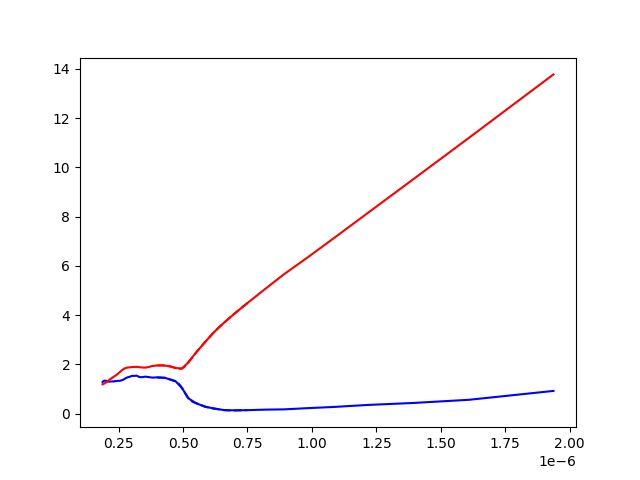

In [130]:
fig = plt.figure()

plt.plot(Lda, Au_n, color='b', label = 'n')
plt.plot(Lda, Au_k, color='r', label = 'k')

plt.plot(Lambda, n(Lambda), color='b', linestyle = '--')
plt.plot(Lambda, k(Lambda), color='r', linestyle = '--')

Create objects

In [131]:
dir_to_save = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study\Ellipsoid simulations\a=50, c=12'
save_data = 0

alpha = 1.42e-5 #in K-1 / thermal expansion coeff
dT=1
a_ini  = 50e-9
c_ini  = 12e-9
eps_ext_ini  = 1.9 *np.ones(np.size(Lambda))
deps_1_ini = 0
deps_2_ini  = 0

# Object in equilibrium

a=a_ini
c=c_ini
eps_ext = eps_ext_ini
deps_1 = deps_1_ini
deps_2 = deps_2_ini
Gold_ellipse = Ellipsoid(a=a, c=c, wl = Lambda, n = n(Lambda), k = k(Lambda), name = 'Gold', polar=(1,0,0), eps_ext= eps_ext, deps_1 = 0, deps_2 = 0)
fname = 'a_{:.2f}_c_{:.2f}_eps_m_{}_deps1_{}_deps2_{}'.format(a*1e9, c*1e9, eps_ext[0], deps_1, deps_2)
if save_data :
    save_spectra_data_excel(fname, dir_to_save, Gold_ellipse)


a=a_ini
c=c_ini
eps_ext = eps_ext_ini
deps_1 = 0.001
deps_2 = deps_2_ini
Gold_ellipse_with_deps_1 = Ellipsoid(a=a, c=c, wl = Lambda, n = n(Lambda), k = k(Lambda), name = 'Gold', polar=(1,0,0), eps_ext= eps_ext, deps_1 = deps_1, deps_2 = deps_2)
fname = 'a_{:.2f}_c_{:.2f}_eps_m_{}_deps1_{}_deps2_{}'.format(a*1e9, c*1e9, eps_ext[0], deps_1, deps_2)
if save_data :
    save_spectra_data_excel(fname, dir_to_save, Gold_ellipse_with_deps_1)

a=a_ini
c=c_ini
eps_ext = eps_ext_ini
deps_1 = deps_1_ini
deps_2 = 0.001
Gold_ellipse_with_deps_2 = Ellipsoid(a=a, c=c, wl = Lambda, n = n(Lambda), k = k(Lambda), name = 'Gold', polar=(1,0,0), eps_ext= eps_ext, deps_1 = deps_1, deps_2 = deps_2)
fname = 'a_{:.2f}_c_{:.2f}_eps_m_{}_deps1_{}_deps2_{}'.format(a*1e9, c*1e9, eps_ext[0], deps_1, deps_2)
if save_data :
    save_spectra_data_excel(fname, dir_to_save, Gold_ellipse_with_deps_2)


a=a_ini + dT*alpha*a_ini
c=c_ini + dT*alpha*c_ini
eps_ext = eps_ext_ini
deps_1 = deps_1_ini
deps_2 = deps_2_ini
Gold_ellipse_with_dilatation = Ellipsoid(a=a, c=c, wl = Lambda, n = n(Lambda), k = k(Lambda), name = 'Gold', polar=(1,0,0), eps_ext= eps_ext, deps_1 = deps_1, deps_2 = deps_2)
fname = 'a_{:.5f}_c_{:.5f}_eps_m_{}_deps1_{}_deps2_{}_dilatation_dT_{}_K'.format(a*1e9, c*1e9, eps_ext[0], deps_1, deps_2, dT)
if save_data :
    save_spectra_data_excel(fname, dir_to_save, Gold_ellipse_with_dilatation)




## Get Stoll table for eps variation

# Get the Jhonson and Christy permittivity.

In [ ]:
# Get the Jhonson and Christy permittivity.
dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study\Acoustic model - data'
fname_eps1 = 'interband_permittivity_change_stoll_2014_eps1.csv'
fname_eps2 = 'interband_permittivity_change_stoll_2014_eps2.csv'

Data ={}
Data['eps1'] ={}
Data['eps2'] ={}

os.chdir(dir_root)
f = pd.read_csv(fname_eps1,sep=";", decimal=",")

Data['eps1']['lambda'] = (f['lambda'].__array__().astype('float64'))*1e-9
Data['eps1']['eV'] = 1240/Data['eps1']['lambda']*1e9
Data['eps1']['Delta_eps1'] = f['Delta eps1 tot (1K)'].__array__().astype('float64')
Data['eps1']['a_ib'] = Data['eps1']['Delta_eps1']/(3*alpha)


os.chdir(dir_root)
f2 = pd.read_csv(fname_eps2,sep=";", decimal=",")
Data['eps2']['lambda'] = (f2['lambda'].__array__())*1e-9
Data['eps2']['eV'] = 1240/Data['eps2']['lambda']*1e9
Data['eps2']['Delta_eps2'] = f2['Delta eps2 tot (1K)'].__array__()
Data['eps2']['b_ib'] = Data['eps2']['Delta_eps2']/(3*alpha)

In [ ]:
f_eps_1_stoll = sc.interpolate.interp1d(Data['eps1']['lambda'],Data['eps1']['Delta_eps1'])
f_eps_2_stoll = sc.interpolate.interp1d(Data['eps2']['lambda'],Data['eps2']['Delta_eps2'])

In [134]:
Ds = {}
Ds['Lambda'] = Lambda
Ds['geometry'] = Gold_ellipse_with_dilatation.sigma_abs - Gold_ellipse.sigma_abs
Ds['eps1'] = (Gold_ellipse_with_deps_1.sigma_abs - Gold_ellipse.sigma_abs)/0.001 * f_eps_1_stoll(Lambda)
Ds['eps2'] = (Gold_ellipse_with_deps_2.sigma_abs - Gold_ellipse.sigma_abs)/0.001 * f_eps_2_stoll(Lambda)
Ds['tot'] = Ds['eps2'] + Ds['eps1'] + Ds['geometry']

C:\Users\nberr\AppData\Local\Temp\ipykernel_3244\1112929791.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


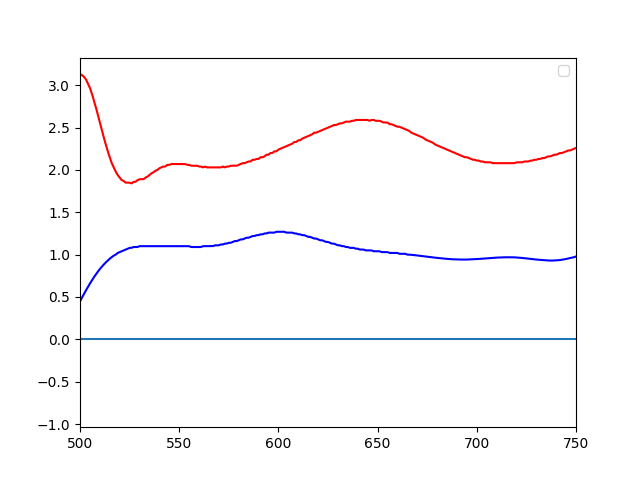

In [135]:
fig, ax = plt.subplots()

ax.plot(Lambda*1e9, f_eps_1_stoll(Lambda)*1e3, color='blue' )
ax.plot(Lambda*1e9, f_eps_2_stoll(Lambda)*1e3, color='red')
ax.set_xlim((500, 750))
ax.axvline(626.5e-9)
ax.axhline(0)
plt.legend()

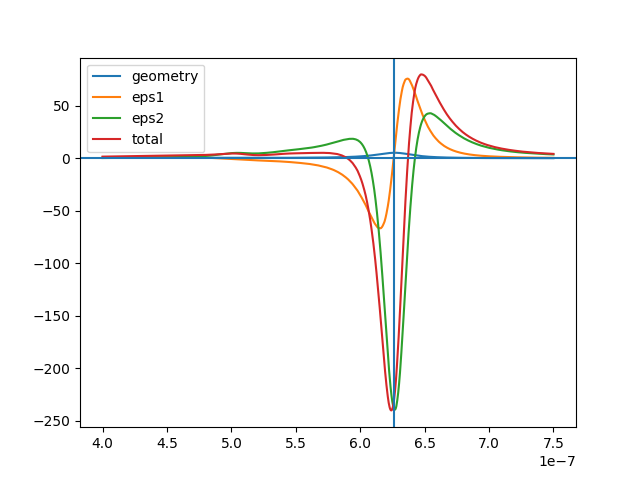

In [136]:
fig, ax = plt.subplots()

ax.plot(Lambda, Ds['geometry']*1e18, label='geometry')
ax.plot(Lambda, Ds['eps1']*1e18, label='eps1')
ax.plot(Lambda, Ds['eps2']*1e18, label='eps2')
ax.plot(Lambda, Ds['tot']*1e18, label='total')
ax.axvline(626.5e-9)
ax.axhline(0)
plt.legend()

In [137]:
dir_to_save = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study\Ellipsoid simulations\a=50, c=12'
save_data = 1
if save_data :
    save_ext_change_data_excel('Extinction change - thermic with Dilatation', dir_to_save, Ds)